![WEkEO Banner](https://github.com/wekeo/frameworks/blob/main/img/WEkEO_banner_partners.png?raw=true)

<div style="display: flex; justify-content: space-between;">
  <a href="./02_Launch_DASK_Cluster_in_the_GUI.ipynb">&lt;&lt; Launch DASK Cluster in the GUI</a>
  <a href="./README.md">README &gt;&gt;</a>
</div>

Copyright (c) 2025 European Union 

License: MIT

# Performance Benchmark of DASK Gateway

**This notebook demonstrates performance benchmarking of the WEkEO DASK Gateway, comparing execution times of the DASK Gateway and local DASK across different data sources.**

[![launch-WEKEO](https://img.shields.io/badge/launch-WEKEO-1a4696.svg)](https://jupyterhub.prod.wekeo2.eu/hub/user-redirect/lab/tree/public/wekeo4data/wekeo-dask/03_Performance_benchmark_of_DASK_Gateway.ipynb)

**PREREQUISITES**

This notebook has the following prerequisites:
- [A WEkEO account](https://my.wekeo.eu/user-registration) 
- Access to the WEkEO JupyterHub workspace
- Completion of [01_Introduction_to_DASK_Gateway.ipynb](./01_Introduction_to_DASK_Gateway.ipynb) or [02_Launch_DASK_Cluster_in_the_GUI.ipynb](./02_Launch_DASK_Cluster_in_the_GUI.ipynb)
- A running DASK cluster on WEkEO
- Basic knowledge of Python and performance profiling

**LEARNING OUTCOMES**

At the end of this notebook you will know: 

- How to benchmark DASK operations for performance analysis
- How to compare execution times with and without DASK Gateway
- How different data sources (in-memory, file-based, object storage) affect performance
- How to identify performance bottlenecks in your workflow
- Best practices for optimizing DASK computations

**CONTENTS**

1. [Local DASK vs. DASK Gateway](#1-local-dask-vs-dask-gateway)  
2. [Setup and imports](#2-setup-and-imports)  
3. [Benchmark](#3-benchmark)  
4. [Baseline performance: local DASK](#4-baseline-performance-local-dask)  
5. [DASK Gateway performance](#5-dask-gateway-performance)  
6. [Performance analysis](#6-performance-analysis)  
7. [Take home messages](#7-take-home-messages)  
8. [Next steps](#8-next-steps)

<hr>

## 1. Local DASK vs. DASK Gateway

What is the difference between "local" DASK and the DASK Gateway? Why do we want to compare the performance of the two solutions? 

### Resource allocation

**Local DASK:** Uses only the resources available on your JupyterHub notebook server. Performance is directly limited by your machine's specifications.

**DASK Gateway:** Allocates resources on separate dedicated worker machines independent of your JupyterHub. You can scale to up to 3 workers workers without affecting notebook performance.

### Data access

**Local DASK:** All data must be loaded through your notebook server's network connection. Accessing data from object storage requires data to travel through the notebook before reaching the worker.

**DASK Gateway:** Workers are closer to the object stores, which speeds up processing including data from object stores. On the other hand, the DASK cluster does not have access to your whole working directory, but only files inside the `processing-results` folder. Be sure to copy data/download data into that folder for processing with DASK

To assess whether it makes sense to use the "local" DASK implementation of the DASK Gateway, you can take the following benchmarking exercise as guidance. 

## 2. Setup and imports

In [1]:
pip install -q h5netcdf

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import required libraries
import dask.array as da
import xarray as xr
import numpy as np
import pandas as pd
import time
from IPython.display import display
import matplotlib.pyplot as plt
import time

# For optional DASK Gateway connection
from dask.distributed import Client
from dask_gateway import Gateway

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"xarray version: {xr.__version__}")

Libraries imported successfully!
NumPy version: 1.26.4
xarray version: 2024.2.0


## 3. Benchmark

The following table summarizes the three scenarios tested in this notebook, and indicates where each is explored in the sections below. All scenarios use datasets of approximately **4 GB**.

| **Scenario** | **With local DASK** | **With DASK Gateway** |
|--------------|---------------------|--------------------|
| **Array Created in Notebook (4 GB)** | Section 4.1 | Section 5.2 |
| **Array Imported from Files (4 GB)** | Section 4.2 | Section 5.3 |
| **Array from Object Storage (4 GB)** | Section 4.3 | Section 5.4 |


## 4. Baseline performance: local DASK

### 4.1 In-memory array computation

In [3]:
# Create a large array using local DASK (no external cluster)
print("Creating large array for local DASK benchmark...")

time_steps = 500
lat_points = 1000
lon_points = 1000

# Create array with local scheduler
local_array = da.random.random(
    (time_steps, lat_points, lon_points),
    chunks=(50, 100, 100)
)

print(f"Array shape: {local_array.shape}")
print(f"Array size: {local_array.nbytes / 1e9:.2f} GB")
print(f"Number of chunks: {local_array.npartitions}")

Creating large array for local DASK benchmark...
Array shape: (500, 1000, 1000)
Array size: 4.00 GB
Number of chunks: 1000


In [4]:
# Benchmark local DASK computation
start_time = time.time()

# Perform computation
mean_result_local = local_array.mean(axis=0).compute()

local_execution_time = time.time() - start_time

print(f"Local DASK execution time: {local_execution_time:.2f} seconds")
print(f"Result shape: {mean_result_local.shape}")

Local DASK execution time: 2.09 seconds
Result shape: (1000, 1000)


### 4.2 File-based data access

In [5]:
# Create and save test dataset
print("Creating test dataset...")

time_ds = np.arange(0, 500)
lat = np.linspace(-90, 90, 1000)
lon = np.linspace(-180, 180, 1000)


data_dask = da.random.random((500, 1000, 1000), chunks=(50, 100, 100))

ds = xr.DataArray(
    data_dask,
    dims=("time", "lat", "lon"),
    coords={"time": time_ds, "lat": lat, "lon": lon},
    name="temperature"
)

# Save to NetCDF file
ds.to_netcdf("/home/jovyan/processing-results/benchmark_data.nc")
print("Test dataset saved to /home/jovyan/processing-results/benchmark_data.nc")

del ds

Creating test dataset...
Test dataset saved to /home/jovyan/processing-results/benchmark_data.nc


In [6]:
# Benchmark file loading with local DASK
print("Loading dataset from file using local DASK...")

start_time = time.time()

# Load dataset with DASK
ds_loaded = xr.open_dataset("/home/jovyan/processing-results/benchmark_data.nc", chunks={"time": 50})

# Perform computation
mean_result_file = ds_loaded.mean(dim="time").compute()

file_execution_time = time.time() - start_time

print(f"File-based local DASK execution time: {file_execution_time:.2f} seconds")

Loading dataset from file using local DASK...
File-based local DASK execution time: 3.01 seconds


### 4.3 Object storage access (S3)

In [7]:
# Setup for object storage access
import os 
import fsspec

print("Setting up object storage access for local DASK...")
print("This example demonstrates access to Copernicus data on S3")

# Configure S3 connection to WEkEO object store
product_id = "large_dataset.nc"
file_path = os.path.join("s3://wekeo/", product_id)
fs = fsspec.filesystem('s3', client_kwargs={'endpoint_url': "https://s3.waw3-2.cloudferro.com/"}, anon=True)

print(f"S3 file path: {file_path}")

Setting up object storage access for local DASK...
This example demonstrates access to Copernicus data on S3
S3 file path: s3://wekeo/large_dataset.nc


In [8]:
# Benchmark local DASK with object storage
print("\nBenchmarking local DASK with S3 object storage access...")

try:
    start_time = time.time()
    
    # Open dataset from S3
    ds_file = fs.open(os.path.join(file_path), 'rb')
    ds_s3_local = xr.open_dataset(ds_file, engine='h5netcdf', chunks={"time": 50})
    
    # Perform computation
    mean_result_s3_local = ds_s3_local.mean(dim="time").compute()
    
    s3_local_execution_time = time.time() - start_time
    
    print(f"Local DASK S3 execution time: {s3_local_execution_time:.2f} seconds")
except Exception as e:
    print(f"S3 access failed (expected if data is not available): {e}")
    s3_local_execution_time = None


Benchmarking local DASK with S3 object storage access...
Local DASK S3 execution time: 44.61 seconds


## 5. DASK Gateway performance

### 5.1 Connect to DASK Gateway cluster

In [9]:
from dask_gateway import Gateway

gateway = Gateway()

clusters = gateway.list_clusters()

if not clusters:
    print("No clusters to close.")
else:
    print(f"Found {len(clusters)} cluster(s). Closing them...")

    for cluster_report in clusters:
        cluster_name = cluster_report.name
        print(f"Closing cluster: {cluster_name}")

        cluster = gateway.connect(cluster_name)
        cluster.shutdown()

    print("All clusters closed.")

Found 2 cluster(s). Closing them...
Closing cluster: ws-jupyterhub.6d46b878fa68464599d3e5b1b3fddd4c
Closing cluster: ws-jupyterhub.172144d5d1b14e2a9f722d25dc214abb
All clusters closed.


In [10]:
from dask_gateway import Gateway
from dask_gateway import GatewayCluster

gateway = Gateway()
options = gateway.cluster_options()

options

# Instantiate a default Dask distributed client to handle data
options.worker_cores = 1
options.worker_memory = 8.0

options

cluster = GatewayCluster(cluster_options=options)

#cluster.adapt(minimum=1, maximum=3)
cluster.scale(3)
cluster

Exception ignored in: <function Gateway.__del__ at 0x7bfa9da4a5c0>
Traceback (most recent call last):
  File "/opt/conda/lib/python3.11/site-packages/dask_gateway/client.py", line 380, in __del__
    self.close()
  File "/opt/conda/lib/python3.11/site-packages/dask_gateway/client.py", line 353, in close
    elif self.loop.asyncio_loop.is_running():
         ^^^^^^^^^
  File "/opt/conda/lib/python3.11/site-packages/dask_gateway/client.py", line 330, in loop
    return self._loop_runner.loop
           ^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.11/site-packages/distributed/utils.py", line 660, in loop
    raise RuntimeError(
RuntimeError: Accessing the loop property while the loop is not running is not supported


### 5.2 In-memory array computation (DASK Gateway)

In [12]:
if gateway is not None:
    print("Benchmarking in-memory computation with DASK Gateway...")
    
    # Create the same array
    gateway_array = da.random.random(
        (500, 1000, 1000),
        chunks=(50, 100, 100)
    )
    
    # Benchmark
    start_time = time.time()
    mean_result_gateway = gateway_array.mean(axis=0).compute()
    gateway_execution_time = time.time() - start_time
    
    print(f"\nDASK Gateway execution time: {gateway_execution_time:.2f} seconds")
    print(f"Local DASK execution time: {local_execution_time:.2f} seconds")
    print(f"Speedup: {local_execution_time / gateway_execution_time:.2f}x")
else:
    print("Skipping DASK Gateway benchmark - no cluster connected")

del gateway_array

Benchmarking in-memory computation with DASK Gateway...

DASK Gateway execution time: 2.11 seconds
Local DASK execution time: 2.09 seconds
Speedup: 0.99x


### 5.3 File-based data access (DASK Gateway)

In [13]:
if gateway is not None:
    print("Benchmarking file-based computation with DASK Gateway...")
    
    # Load the same file
    start_time = time.time()
    ds_gateway = xr.open_dataset("/home/jovyan/processing-results/benchmark_data.nc", chunks={"time": 50})
    mean_result_gateway_file = ds_gateway.mean(dim="time").compute()
    gateway_file_execution_time = time.time() - start_time
    
    print(f"\nDASK Gateway execution time: {gateway_file_execution_time:.2f} seconds")
    print(f"Local DASK execution time: {file_execution_time:.2f} seconds")
    print(f"Speedup: {file_execution_time / gateway_file_execution_time:.2f}x")
else:
    print("Skipping DASK Gateway benchmark - no cluster connected")

Benchmarking file-based computation with DASK Gateway...

DASK Gateway execution time: 8.41 seconds
Local DASK execution time: 3.01 seconds
Speedup: 0.36x


### 5.4 Object storage access (S3) (DASK Gateway)

In [14]:
import os 
import fsspec
import xarray as xr
product_id = "large_dataset.nc"
file_path = os.path.join("s3://wekeo/", product_id)
fs = fsspec.filesystem('s3', client_kwargs={'endpoint_url': "https://s3.waw3-2.cloudferro.com/"}, anon=True)


In [15]:
if gateway is not None:
    print("Benchmarking object storage (S3) with DASK Gateway...")
    
    try:
        # Benchmark
        start_time = time.time()
        
        # Open dataset from S3
        ds_file_gateway = fs.open(os.path.join(file_path), 'rb')
        ds_s3_gateway = xr.open_dataset(ds_file_gateway, engine='h5netcdf', chunks={"time": 50})
        
        # Perform computation
        mean_result_s3_gateway = ds_s3_gateway.mean(dim="time").compute()
        
        s3_gateway_execution_time = time.time() - start_time
        
        print(f"\nDASK Gateway S3 execution time: {s3_gateway_execution_time:.2f} seconds")
        if s3_local_execution_time is not None:
            print(f"Local DASK S3 execution time: {s3_local_execution_time:.2f} seconds")
            print(f"Speedup: {s3_local_execution_time / s3_gateway_execution_time:.2f}x")
    except Exception as e:
        print(f"S3 access failed on gateway (expected if data is not available): {e}")
        s3_gateway_execution_time = None
else:
    print("Skipping object storage benchmark - no cluster connected")
    s3_gateway_execution_time = None

Benchmarking object storage (S3) with DASK Gateway...

DASK Gateway S3 execution time: 43.14 seconds
Local DASK S3 execution time: 44.61 seconds
Speedup: 1.03x


### 5.5 Close cluster connection

In [16]:
# Close your client connection
cluster.shutdown()
print("Cluster shut down.")

Cluster shut down.


## 6. Performance analysis

### 6.1 Create benchmark summary

In [18]:
# Create summary dataframe
results = {
    'Scenario': ['In-Memory Array', 'File-Based Access', 'Object Storage (S3)'],
    'Local DASK (s)': [local_execution_time, file_execution_time, s3_local_execution_time]
}

if gateway is not None:
    results['DASK Gateway (s)'] = [gateway_execution_time, gateway_file_execution_time, s3_gateway_execution_time]
    results['Speedup'] = [
        local_execution_time / gateway_execution_time,
        file_execution_time / gateway_file_execution_time,
        s3_local_execution_time / s3_gateway_execution_time if (s3_local_execution_time and s3_gateway_execution_time) else None
    ]

results_df = pd.DataFrame(results)
print("\nBenchmark Results Summary:")
print(results_df.to_string(index=False))


Benchmark Results Summary:
           Scenario  Local DASK (s)  DASK Gateway (s)  Speedup
    In-Memory Array        2.093573          2.114017 0.990329
  File-Based Access        3.011875          8.408365 0.358200
Object Storage (S3)       44.607392         43.138308 1.034055


### 6.2 Visualize results

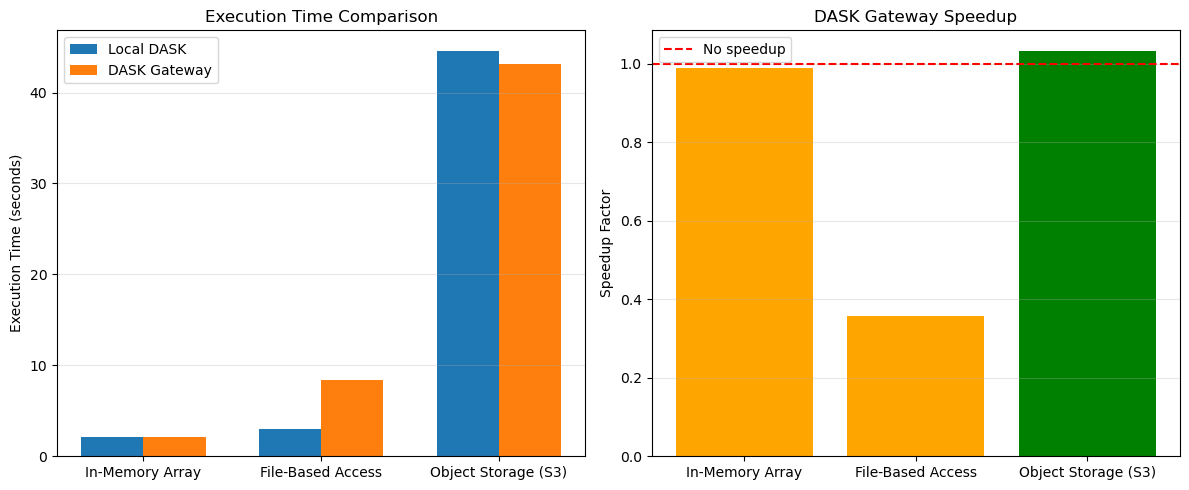

In [20]:
if gateway is not None:
    # Create comparison visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Execution time comparison
    scenarios = results_df['Scenario']
    x = np.arange(len(scenarios))
    width = 0.35
    
    ax1.bar(x - width/2, results_df['Local DASK (s)'], width, label='Local DASK')
    ax1.bar(x + width/2, results_df['DASK Gateway (s)'], width, label='DASK Gateway')
    ax1.set_ylabel('Execution Time (seconds)')
    ax1.set_title('Execution Time Comparison')
    ax1.set_xticks(x)
    ax1.set_xticklabels(scenarios)
    ax1.legend()
    ax1.grid(axis='y', alpha=0.3)
    
    # Speedup visualization
    ax2.bar(scenarios, results_df['Speedup'], color=['green' if s > 1 else 'orange' for s in results_df['Speedup']])
    ax2.axhline(y=1, color='red', linestyle='--', label='No speedup')
    ax2.set_ylabel('Speedup Factor')
    ax2.set_title('DASK Gateway Speedup')
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print("Cannot visualize - no DASK Gateway cluster connected")

## 7. Take home messages

### Key findings

#### 1. In-memory data

When the data is already loaded in memory, using a DASK Gateway cluster provides **no benefit**. The overhead of distributing tasks to remote workers slightly reduces performance.

**Conclusion:**  
Use Local DASK when working with in-memory data.

---

#### 2. File-based access (local working directory)

When reading files from the local working directory, Local DASK is significantly faster than the DASK Gateway cluster.

This is because:

- Local DASK workers have direct access to the local filesystem.
- Gateway workers must access the data over the network.
- Network latency and data transfer overhead reduce performance.

**Conclusion:**  
Use Local DASK when your data is stored in the working directory.

---

#### 3. Object storage (S3)

When accessing data from object storage, the DASK Gateway cluster performs slightly better.

This is because:

- Gateway workers are located closer to the object storage.
- Multiple workers can download and process data in parallel.
- This reduces the impact of network latency and improves scalability.

**Conclusion:**  
Use a DASK Gateway cluster when working with data stored in object storage (S3).

<hr>

## 8. Next steps

Now that you've benchmarked DASK Gateway performance:

- **Apply to real data**: Use these techniques with actual Copernicus data from the WEkEO Data Store
- **Profile your workflows**: Benchmark your own computations to identify bottlenecks
- **Optimize configurations**: Experiment with different worker counts and chunk sizes
- **Review other tutorials**:
  - [01_Introduction_to_DASK_Gateway.ipynb](./01_Introduction_to_DASK_Gateway.ipynb) - Programmatic cluster creation
  - [02_Launch_DASK_Cluster_in_the_GUI.ipynb](./02_Launch_DASK_Cluster_in_the_GUI.ipynb) - GUI-based cluster launching

### Additional resources:

- [DASK Performance Tuning](https://docs.dask.org/en/latest/develop.html)
- [DASK Diagnostics](https://docs.dask.org/en/latest/diagnostics-distributed.html)
- [WEkEO Help Center](https://help.wekeo.eu/)

<hr>

[View on GitHub](https://github.com/wekeo) | 
[Visit WEkEO](https://wekeo.copernicus.eu) | 
[Run Notebooks on the WEkEO Workspace](https://jupyterhub.prod.wekeo2.eu/) | 
[Contact helpdesk for support](mailto:support@wekeo.eu)